In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

df = sns.load_dataset("mpg")

In [2]:
df.head(10)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
5,15.0,8,429.0,198.0,4341,10.0,70,usa,ford galaxie 500
6,14.0,8,454.0,220.0,4354,9.0,70,usa,chevrolet impala
7,14.0,8,440.0,215.0,4312,8.5,70,usa,plymouth fury iii
8,14.0,8,455.0,225.0,4425,10.0,70,usa,pontiac catalina
9,15.0,8,390.0,190.0,3850,8.5,70,usa,amc ambassador dpl


In [12]:
# 1. Carga `auto_mpg.csv` y realiza el primer contacto con el dataset. Reporta dimensiones, 
# primeras filas, tipos de datos y define qué representa una fila. 


In [10]:
df.shape

(398, 9)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [7]:
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin              str
name                str
dtype: object

In [14]:
# 2. Clasifica `mpg`, `cylinders`, `displacement`, `horsepower`, `weight`, `acceleration`, 
# `model_year`, `origin` y `name`. Identifica qué variables, aunque puedan verse numéricas, 
# conviene tratar como categorías o variables temporales.

clasificacion_variables = pd.DataFrame({
    "variable": [
        "mpg", 
        "cylinders", 
        "displacement", 
        "horspower", 
        "weight", 
        "acceleration", 
        "model_year", 
        "origin", 
        "name"
        ],
        "clasificacion": [
            "numerica - continua",
            "categorica - discreta",
            "numerica - continua",
            "numerica - continua",
            "numerica - continua",
            "numerica - continua",
            "categorica - nominal",
            "numerica - discreta",
            "categorica - nominal",
        ]
})
clasificacion_variables

,variable,clasificacion
0,mpg,numerica - continua
1,cylinders,categorica - discreta
2,displacement,numerica - continua
3,horspower,numerica - continua
4,weight,numerica - continua
5,acceleration,numerica - continua
6,model_year,categorica - nominal
7,origin,numerica - discreta
8,name,categorica - nominal


In [49]:
# 3. Analiza valores faltantes y duplicados exactos. ¿En qué variable faltan datos y qué 
# proporción representan?
# Pista de trabajo: Para una correlación puntual puedes trabajar con pares completos sin alterar toda la tabla.  

valores_faltantes = df.isna().sum()
valores_duplicados= df.duplicated().sum()

print(valores_faltantes),
print("="*20),
print("Duplicados:", valores_duplicados)



mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
hp_null         0
dtype: int64
Duplicados: 0


In [2]:
# 4. Estudia la cardinalidad de `name`. ¿Cuántos nombres distintos hay? ¿Que un nombre 
# aparezca varias veces significa que las filas son duplicadas? Compruébalo con ejemplos. 
# Pista de trabajo: Un mismo modelo de automóvil puede aparecer en años o configuraciones diferentes.

nombres_distintos = df["name"].nunique()
nombres_repetidos = df["name"].value_counts()

print("Nombres distintos:", nombres_distintos)
print("\nNombres que más se repiten:")
print(nombres_repetidos.head(10))

nombre_ejemplo = nombres_repetidos[nombres_repetidos > 1].index[0]
print("\nEjemplo de un nombre repetido:", nombre_ejemplo)

df[df["name"] == nombre_ejemplo]

Nombres distintos: 305

Nombres que más se repiten:
name
ford pinto            6
ford maverick         5
amc matador           5
toyota corolla        5
chevrolet impala      4
amc hornet            4
peugeot 504           4
amc gremlin           4
toyota corona         4
chevrolet chevette    4
Name: count, dtype: int64

Ejemplo de un nombre repetido: ford pinto


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
32,25.0,4,98.0,NaN,2046,19.0,71,usa,ford pinto
112,19.0,4,122.0,85.0,2310,18.5,73,usa,ford pinto
130,26.0,4,122.0,80.0,2451,16.5,74,usa,ford pinto
168,23.0,4,140.0,83.0,2639,17.0,75,usa,ford pinto
174,18.0,6,171.0,97.0,2984,14.5,75,usa,ford pinto
206,26.5,4,140.0,72.0,2565,13.6,76,usa,ford pinto


In [24]:
# 5. Calcula estadísticos descriptivos de `mpg`, `weight` y `horsepower`: media, mediana, 
# desviación estándar, cuartiles e IQR. Interpreta qué te dicen sobre un automóvil “típico” y 
# sobre la dispersión.

cols = ['mpg', 'weight', 'horsepower']
stats = df[cols].agg(['mean', 'median', 'std']).T
stats['Q1'] = df[cols].quantile(0.25)
stats['Q3'] = df[cols].quantile(0.75)
stats['IQR'] = stats['Q3'] - stats['Q1']
print(stats)

                   mean  median         std       Q1      Q3      IQR
mpg           23.514573    23.0    7.815984    17.50    29.0    11.50
weight      2970.424623  2803.5  846.841774  2223.75  3608.0  1384.25
horsepower   104.469388    93.5   38.491160    75.00   126.0    51.00


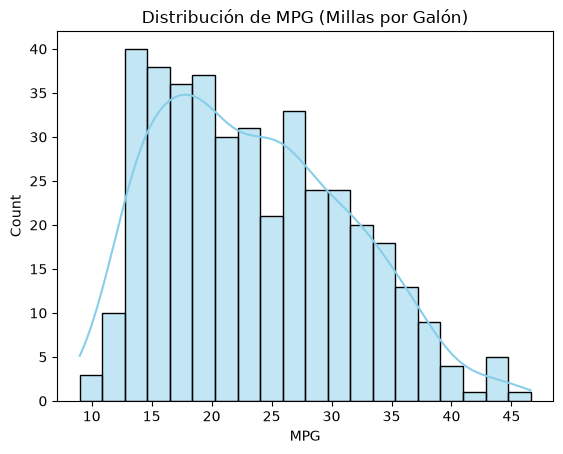

In [25]:
# 6. Analiza la distribución de `mpg` con histograma y KDE. 

plt.figure()
sns.histplot(df['mpg'], kde=True, bins=20, color='skyblue')
plt.title("Distribución de MPG (Millas por Galón)")
plt.xlabel("MPG")
plt.show()

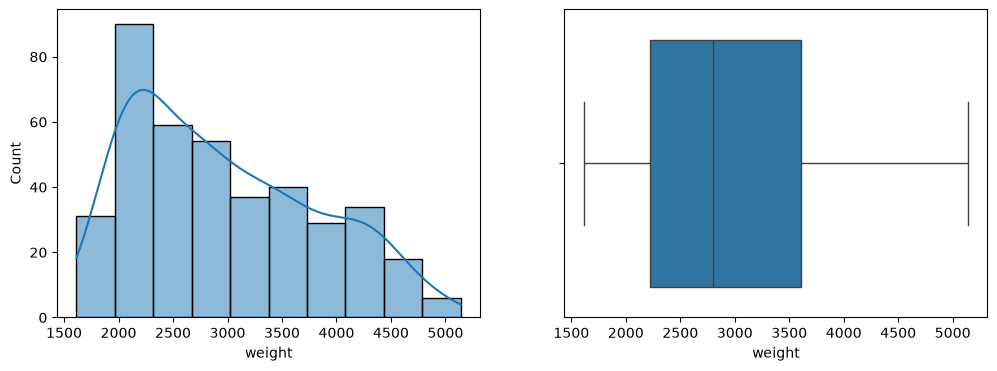

Límite inferior: 147.375, Límite superior: 5684.375
Outliers detectados en weight: 0


In [26]:
# 7. Analiza `weight` con histograma y boxplot. ¿La distribución es simétrica? ¿Hay valores 
# extremos según la regla del IQR? Documenta el cálculo. 

Q1 = df['weight'].quantile(0.25)
Q3 = df['weight'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['weight'], kde=True, ax=axes[0])
sns.boxplot(x=df['weight'], ax=axes[1])
plt.show()

print(f"Límite inferior: {lower_bound}, Límite superior: {upper_bound}")
outliers_w = df[(df['weight'] < lower_bound) | (df['weight'] > upper_bound)]
print(f"Outliers detectados en weight: {len(outliers_w)}")

In [27]:
# 8. Detecta outliers en `horsepower` usando 1.5·IQR. Lista los vehículos identificados y 
# comenta si parecen errores evidentes o automóviles de alta potencia plausibles. 
# Pista de trabajo: Conserva el nombre del vehículo para interpretar el contexto del outlier.

hp = df['horsepower'].dropna()
q1_hp, q3_hp = hp.quantile(0.25), hp.quantile(0.75)
iqr_hp = q3_hp - q1_hp
sup_hp = q3_hp + 1.5 * iqr_hp

outliers_hp = df[df['horsepower'] > sup_hp]
print(outliers_hp[['name', 'horsepower', 'cylinders', 'model_year']])

                             name  horsepower  cylinders  model_year
6                chevrolet impala       220.0          8          70
7               plymouth fury iii       215.0          8          70
8                pontiac catalina       225.0          8          70
13        buick estate wagon (sw)       225.0          8          70
25                      ford f250       215.0          8          70
27                     dodge d200       210.0          8          70
67                mercury marquis       208.0          8          72
94   chrysler new yorker brougham       215.0          8          73
95       buick electra 225 custom       225.0          8          73
116            pontiac grand prix       230.0          8          73


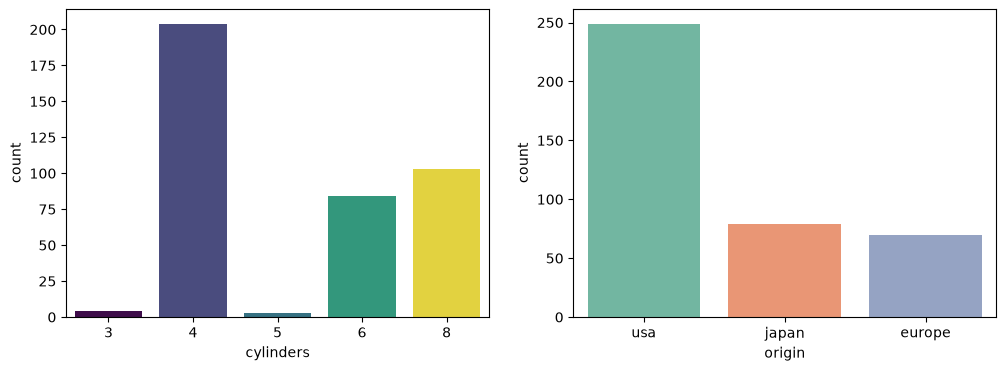

In [29]:
# 9. Explora `cylinders` y `origin` mediante frecuencias y gráficos de barras. ¿Qué categorías 
# dominan el dataset? ¿Hay categorías con muy pocos casos? 
# Pista de trabajo: Las categorías poco frecuentes pueden hacer inestables algunas comparaciones. 

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x='cylinders', ax=axes[0], hue='cylinders', palette='viridis', legend=False)
sns.countplot(data=df, x='origin', ax=axes[1], hue='origin', palette='Set2', legend=False)

plt.show()

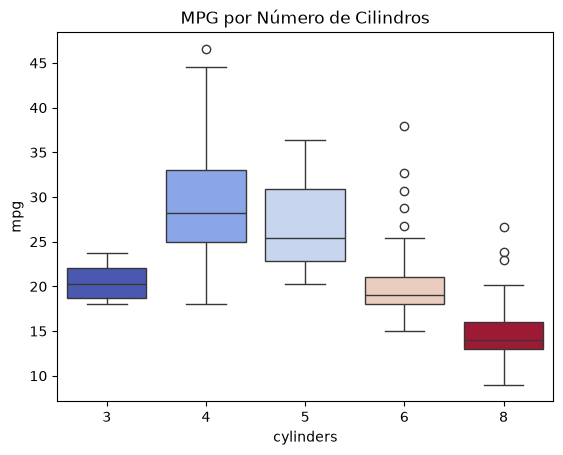

                mean  median  count
cylinders                          
3          20.550000   20.25      4
4          29.286765   28.25    204
5          27.366667   25.40      3
6          19.985714   19.00     84
8          14.963107   14.00    103


In [31]:
# 10. Compara `mpg` entre vehículos con distinto número de cilindros mediante boxplot y 
# medias/medianas por grupo. ¿Qué patrón general observas? 
# Pista de trabajo: Ordena los cilindros numéricamente. 

sns.boxplot(data=df, x='cylinders', y='mpg', hue='cylinders', palette='coolwarm', legend=False)
plt.title("MPG por Número de Cilindros")
plt.show()

print(df.groupby('cylinders')['mpg'].agg(['mean', 'median', 'count']))

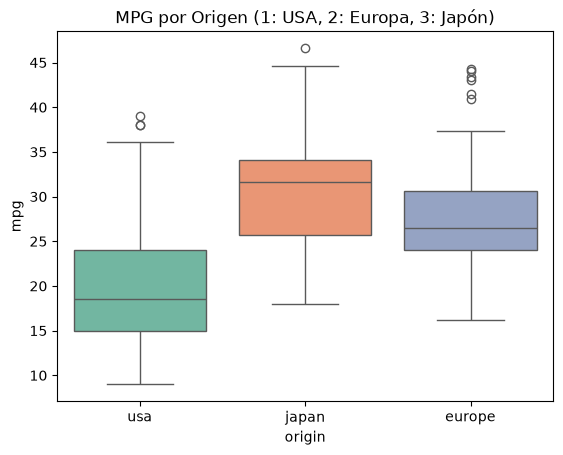

             mean  median       std
origin                             
europe  27.891429    26.5  6.723930
japan   30.450633    31.6  6.090048
usa     20.083534    18.5  6.402892


In [32]:
# 11. Compara `mpg` entre los tres orígenes del dataset. Usa boxplot y estadísticas por grupo.  
# Pista de trabajo: Las diferencias de origen pueden estar mezcladas con peso, cilindrada, año y otras 
# variables. 
sns.boxplot(data=df, x='origin', y='mpg', hue='origin', palette='Set2', legend=False)
plt.title("MPG por Origen (1: USA, 2: Europa, 3: Japón)")
plt.show()

print(df.groupby('origin')['mpg'].agg(['mean', 'median', 'std']))

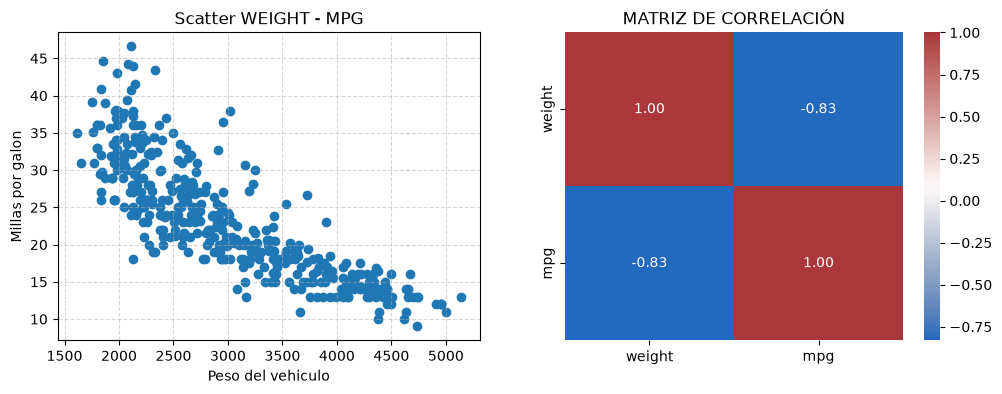

<Figure size 1000x800 with 0 Axes>

In [7]:
# 12. Estudia la relación entre `weight` y `mpg` con un scatterplot y la correlación.

dashboard, axes = plt.subplots(1,2 , figsize=(12, 4))

axes[0].scatter(df["weight"],df["mpg"])
axes[0].set_xlabel('Peso del vehiculo')
axes[0].set_ylabel('Millas por galon')
axes[0].set_title('Scatter WEIGHT - MPG')
axes[0].grid(True, linestyle="--", alpha=0.5)
#FIGURA 2 
plt.figure(figsize=(10,8))
corr = df[["weight", "mpg"]].corr()
sns.heatmap(corr,ax=axes[1],annot=True,fmt=".2f",cmap="vlag")
axes[1].set_title("MATRIZ DE CORRELACIÓN")

plt.show()


Text(0.5, 1.0, 'MATRIZ DE CORRELACIÓN')

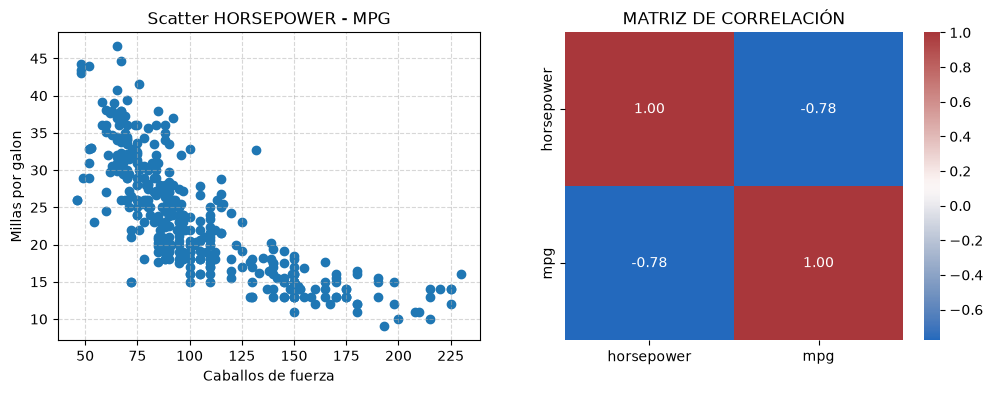

<Figure size 1000x800 with 0 Axes>

In [8]:
# 13. Estudia la relación entre `horsepower` y `mpg` con scatterplot y correlación. Compara su 
# intensidad con la relación `weight`–`mpg`.

df_copy=df.copy()
df_copy = df_copy.dropna(subset=["horsepower"])

dashboard, axes = plt.subplots(1,2 , figsize=(12, 4))

axes[0].scatter(df_copy["horsepower"],df_copy["mpg"])
axes[0].set_xlabel('Caballos de fuerza')
axes[0].set_ylabel('Millas por galon')
axes[0].set_title('Scatter HORSEPOWER - MPG')
axes[0].grid(True, linestyle="--", alpha=0.5)
#FIGURA 2 
plt.figure(figsize=(10,8))
corr = df_copy[["horsepower", "mpg"]].corr()
sns.heatmap(corr,ax=axes[1],annot=True,fmt=".2f",cmap="vlag")
axes[1].set_title("MATRIZ DE CORRELACIÓN")

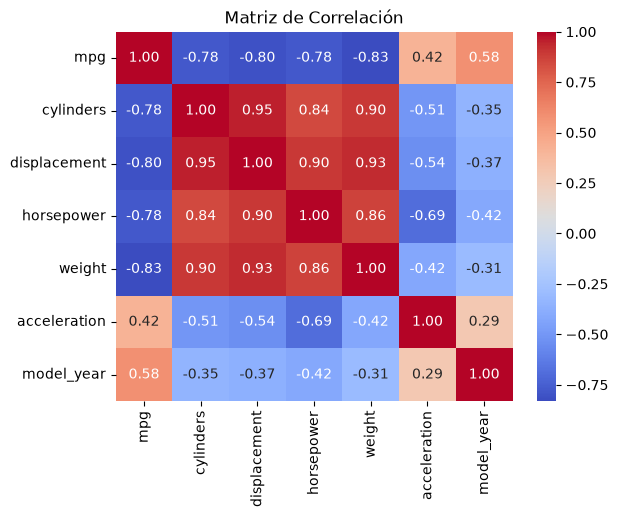

Correlación de las variables con MPG:
weight         -0.831741
displacement   -0.804203
horsepower     -0.778427
cylinders      -0.775396
acceleration    0.420289
model_year      0.579267
mpg             1.000000
Name: mpg, dtype: float64


In [37]:
 
# 14. Construye una matriz de correlación y heatmap de las variables numéricas. Identifica las 
# tres variables con mayor asociación lineal absoluta con `mpg` y comenta posibles 
# redundancias entre predictores. 
# Pista de trabajo: La matriz es simétrica; no hace falta interpretar dos veces cada pareja. 


numeric_cols = df.select_dtypes(include='number').columns
corr_matrix = df[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de Correlación")
plt.show()

print("Correlación de las variables con MPG:")
print(corr_matrix['mpg'].sort_values())

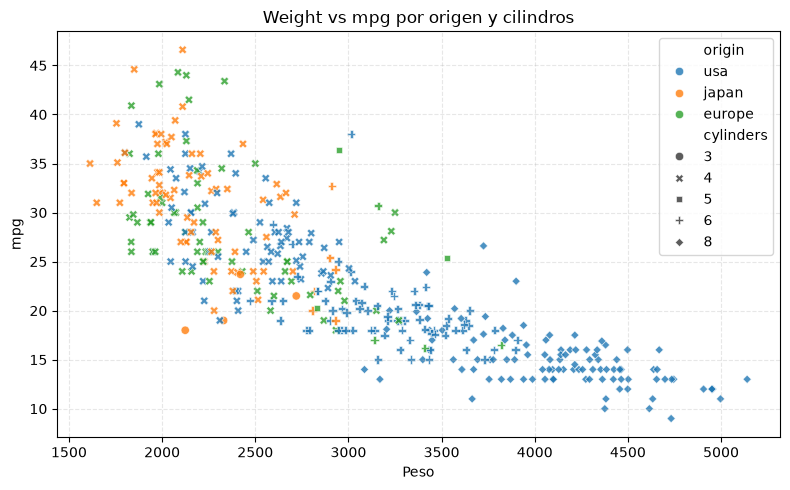

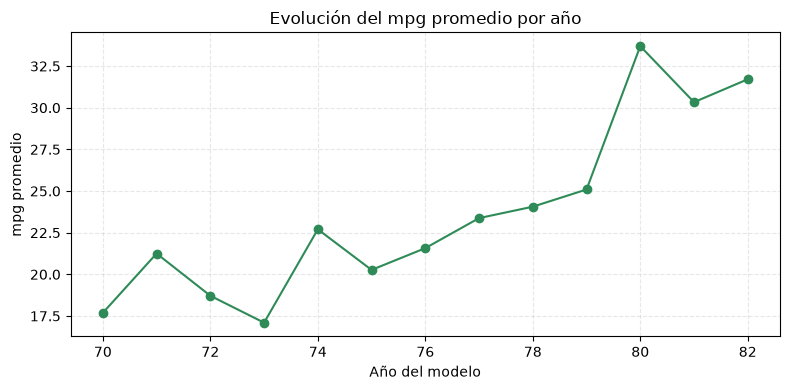

In [11]:
# 15. Realiza un análisis multivariado de `weight` frente a `mpg` incorporando `origin` y 
# `cylinders` (mediante color, estilo, facetas u otra codificación). Añade la evolución media de 
# `mpg` por `model_year`. 
# Pista de trabajo: Busca si el patrón peso–consumo se mantiene dentro de distintos grupos y cómo cambia 
# con el tiempo. 

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="weight",
    y="mpg",
    hue="origin",
    style="cylinders",
    alpha=0.8
)
plt.title("Weight vs mpg por origen y cilindros")
plt.xlabel("Peso")
plt.ylabel("mpg")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

mpg_promedio_anual = df.groupby("model_year")["mpg"].mean()

plt.figure(figsize=(8, 4))
plt.plot(mpg_promedio_anual.index, mpg_promedio_anual.values, marker="o", color="seagreen")
plt.title("Evolución del mpg promedio por año")
plt.xlabel("Año del modelo")
plt.ylabel("mpg promedio")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

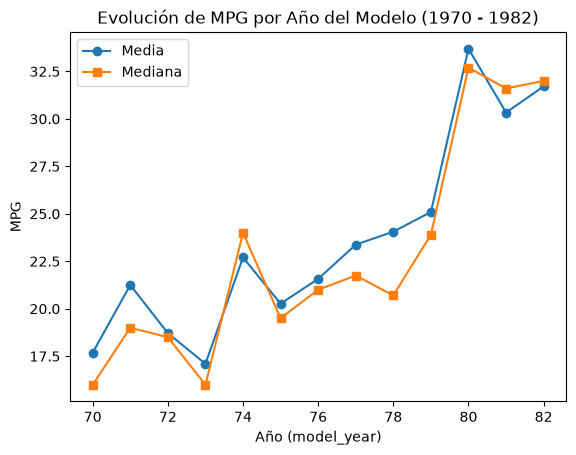

In [39]:
# 16. Analiza la evolución de `mpg` por `model_year`. Calcula media y mediana por año y 
# represéntalas en una gráfica de líneas.  
# Pista de trabajo: Trata `model_year` como una variable temporal discreta y revisa todos los años, no solo el 
# primero y el último. 

evolution = df.groupby('model_year')['mpg'].agg(['mean', 'median']).reset_index()
plt.plot(evolution['model_year'], evolution['mean'], label='Media', marker='o')
plt.plot(evolution['model_year'], evolution['median'], label='Mediana', marker='s')
plt.title("Evolución de MPG por Año del Modelo (1970 - 1982)")
plt.xlabel("Año (model_year)")
plt.ylabel("MPG")
plt.legend()
plt.show()

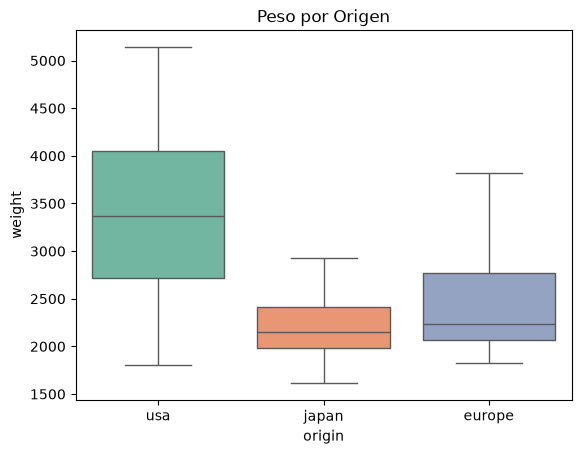

origin
europe    2423.300000
japan     2221.227848
usa       3361.931727
Name: weight, dtype: float64


In [40]:
# 17. Compara el `weight` de los automóviles por `origin` mediante estadísticas y boxplots. 
# ¿Puede la diferencia de peso ayudar a explicar parte de las diferencias de `mpg` observadas 
# entre orígenes? 
# Pista de trabajo: Relaciona este resultado con la fuerte asociación entre peso y consumo observada 
# previamente. 

sns.boxplot(data=df, x='origin', y='weight', hue='origin', palette='Set2', legend=False)
plt.title("Peso por Origen")
plt.show()

print(df.groupby('origin')['weight'].mean())

In [13]:
# 18. Estudia el patrón de los valores faltantes de `horsepower`. Compara su frecuencia por 
# `origin`, `cylinders` y `model_year`.  
# Pista de trabajo: Con pocos casos faltantes conviene describir el patrón, pero evitar conclusiones fuertes. 

df["horsepower_faltante"] = df["horsepower"].isna()

nulos_por_origen = df.groupby("origin")["horsepower_faltante"].agg(["sum", "mean"])
nulos_por_cilindros = df.groupby("cylinders")["horsepower_faltante"].agg(["sum", "mean"])
nulos_por_anio = df.groupby("model_year")["horsepower_faltante"].agg(["sum", "mean"])

nulos_por_origen["mean"] = (nulos_por_origen["mean"] * 100).round(2)
nulos_por_cilindros["mean"] = (nulos_por_cilindros["mean"] * 100).round(2)
nulos_por_anio["mean"] = (nulos_por_anio["mean"] * 100).round(2)

print("Nulos por origen:")
print(nulos_por_origen)
print("\nNulos por cilindros:")
print(nulos_por_cilindros)
print("\nAños con nulos:")
print(nulos_por_anio[nulos_por_anio["sum"] > 0])

Nulos por origen:
        sum  mean
origin           
europe    2  2.86
japan     0  0.00
usa       4  1.61

Nulos por cilindros:
           sum  mean
cylinders           
3            0  0.00
4            5  2.45
5            0  0.00
6            1  1.19
8            0  0.00

Años con nulos:
            sum  mean
model_year           
71            1  3.57
74            1  3.70
80            2  6.90
81            1  3.45
82            1  3.23


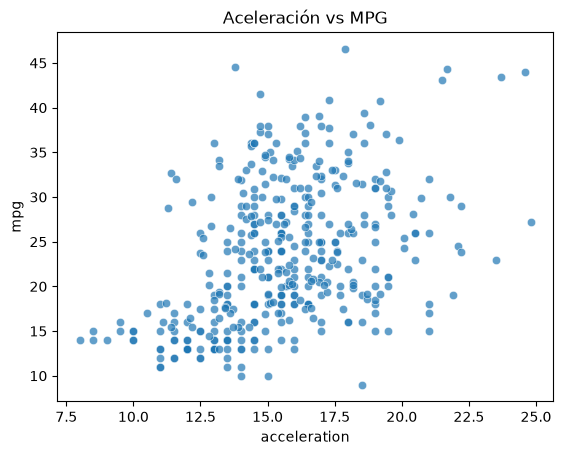

Correlación Aceleración - MPG: 0.42028891210165065


In [42]:

# 19. Analiza la relación entre `acceleration` y `mpg` mediante scatterplot y correlación de 
# Pearson. Compara su fuerza con las relaciones de `weight` y `horsepower` con `mpg`. 
# Pista de trabajo: Una correlación moderada puede aportar información, pero no necesariamente domina el 
# comportamiento del objetivo. 

sns.scatterplot(data=df, x='acceleration', y='mpg', alpha=0.7)
plt.title("Aceleración vs MPG")
plt.show()
print("Correlación Aceleración - MPG:", df['acceleration'].corr(df['mpg']))

              displacement  horsepower    weight
displacement      1.000000    0.897257  0.932824
horsepower        0.897257    1.000000  0.864538
weight            0.932824    0.864538  1.000000


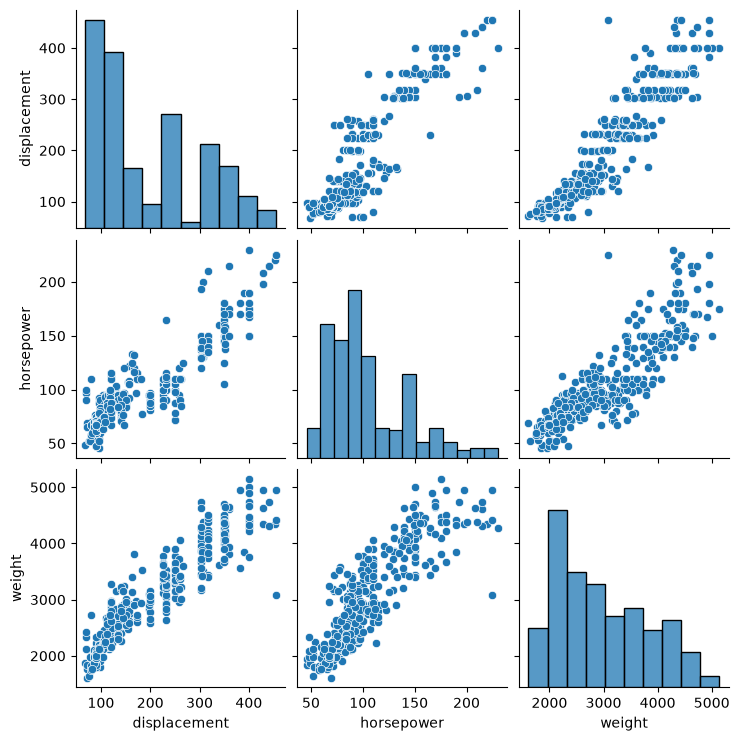

In [43]:
# 20. Explora las relaciones entre `displacement`, `horsepower` y `weight`. Calcula sus 
# correlaciones y crea gráficos de dispersión. ¿Qué problema podría aparecer si se usan 
# simultáneamente como predictores sin revisar redundancias? 
# Pista de trabajo: Correlaciones muy altas entre predictores son una señal de posible multicolinealidad o 
# redundancia. 

cols_red = ['displacement', 'horsepower', 'weight']
print(df[cols_red].corr())
sns.pairplot(df[cols_red].dropna())
plt.show()

In [44]:

# 21. Construye una tabla pivote con el `mpg` medio por `cylinders` y `origin`, incluyendo el 
# número de automóviles por grupo. ¿El patrón de cilindros se mantiene dentro de cada origen? 
# Señala grupos con muestras pequeñas. 
# Pista de trabajo: No interpretes con la misma confianza una media basada en 3 automóviles que otra basada 
# en más de 60. 

pivot_table = df.pivot_table(
    index='cylinders', 
    columns='origin', 
    values='mpg', 
    aggfunc=['mean', 'count']
)
print(pivot_table)

                mean                        count             
origin        europe      japan        usa europe japan    usa
cylinders                                                     
3                NaN  20.550000        NaN    NaN   4.0    NaN
4          28.411111  31.595652  27.840278   63.0  69.0   72.0
5          27.366667        NaN        NaN    3.0   NaN    NaN
6          20.100000  23.883333  19.663514    4.0   6.0   74.0
8                NaN        NaN  14.963107    NaN   NaN  103.0


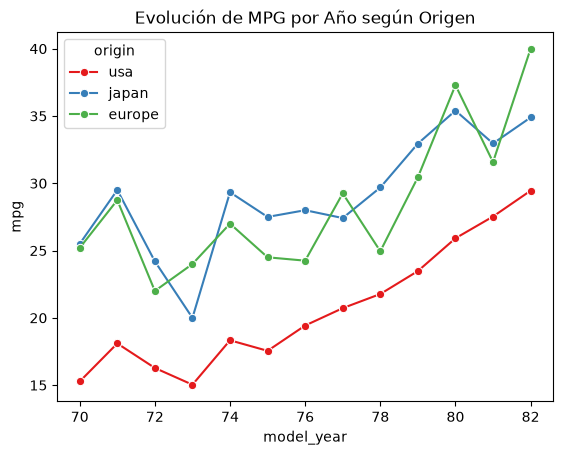

In [45]:
# 22. Compara la evolución temporal de `mpg` entre `origin` usando líneas por grupo. ¿Los tres 
# orígenes mejoran con el tiempo? ¿La brecha entre orígenes permanece constante? 
# Pista de trabajo: Una gráfica con `model_year` en x, `mpg` medio en y y una línea por origen permite ver 
# interacción entre tiempo y origen. 

sns.lineplot(data=df, x='model_year', y='mpg', hue='origin', marker='o', errorbar=None, palette='Set1')
plt.title("Evolución de MPG por Año según Origen")
plt.show()

In [ ]:
# 23. Compara los outliers de `horsepower` detectados mediante 1.5·IQR y mediante |z| > 3. 
# Lista los vehículos más extremos y explica por qué un método puede ser más estricto que el 
# otro en una distribución asimétrica. 
# Pista de trabajo: Comprueba la intersección entre ambos conjuntos de outliers en lugar de asumir que 
# producen la misma lista. 

hp_series = df['horsepower'].dropna()


q1_h = hp_series.quantile(0.25)
q3_h = hp_series.quantile(0.75)
sup_iqr = q3_h + 1.5 * (q3_h - q1_h)
outliers_iqr = set(df[df['horsepower'] > sup_iqr]['name'])


mean_hp = hp_series.mean()
std_hp = hp_series.std()
sup_z = mean_hp + 3 * std_hp
outliers_z = set(df[df['horsepower'] > sup_z]['name'])

print("Outliers por IQR:", len(outliers_iqr))
print("Outliers por Z-score:", len(outliers_z))
print("Intersección:", outliers_iqr.intersection(outliers_z))

Outliers por IQR: 10
Outliers por Z-score: 5
Intersección: {'chevrolet impala', 'pontiac catalina', 'pontiac grand prix', 'buick estate wagon (sw)', 'buick electra 225 custom'}


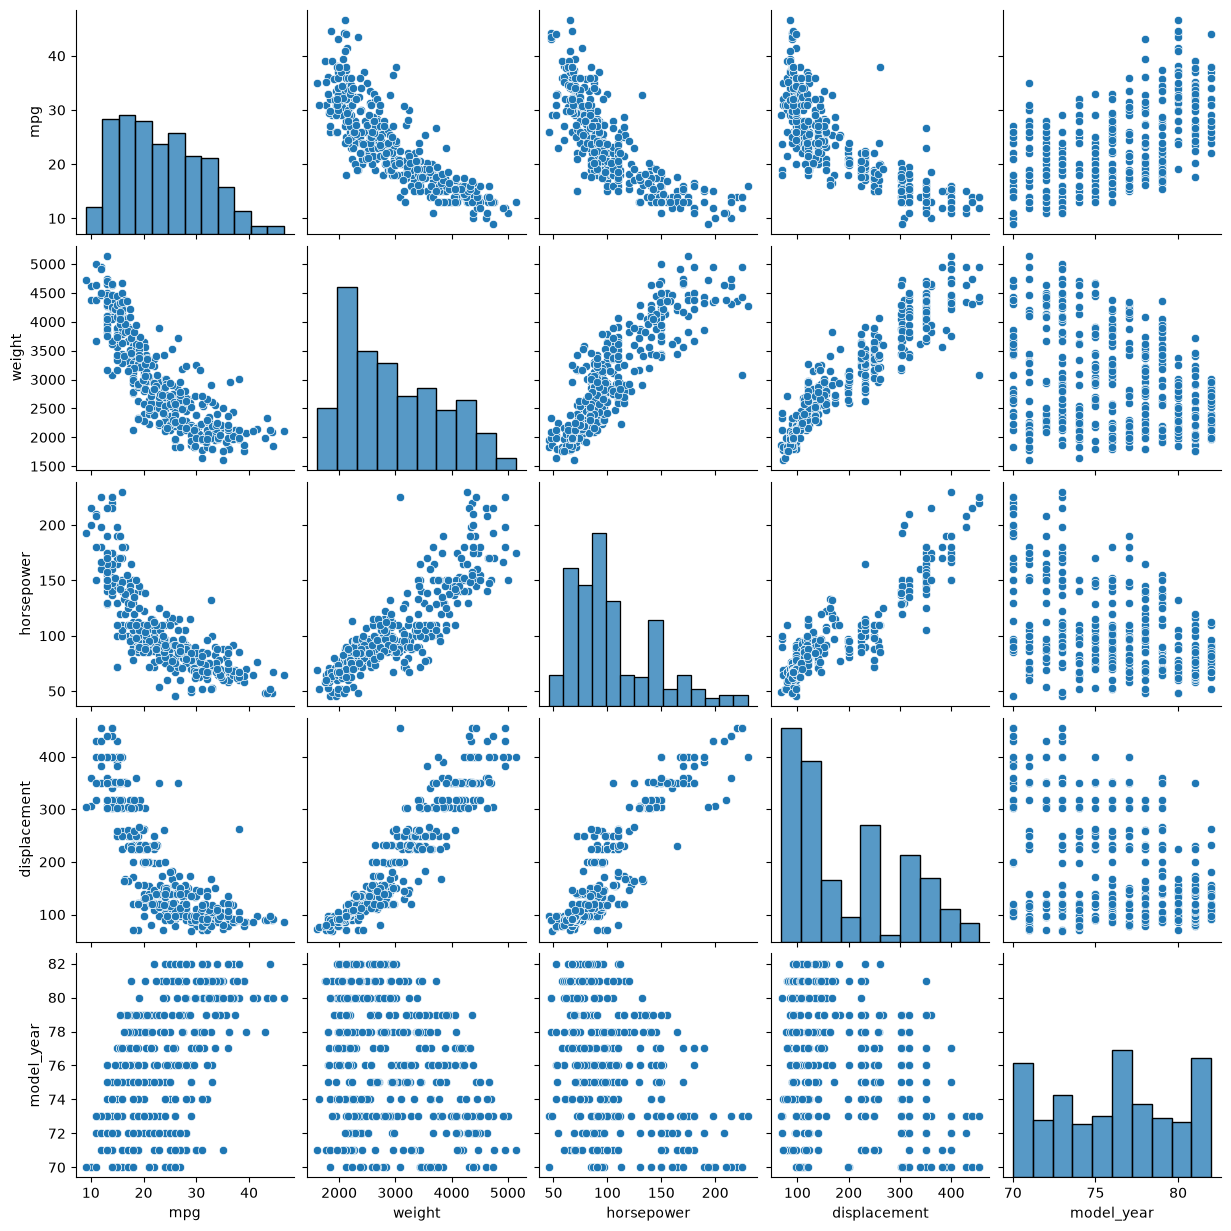

In [47]:
# 24. Construye un `pairplot` con `mpg`, `weight`, `horsepower`, `displacement` y 
# `model_year`, usando `origin` como color. 

cols_pair = ['mpg', 'weight', 'horsepower', 'displacement', 'model_year']
sns.pairplot(df[cols_pair].dropna())
plt.show()

In [48]:
# 25. Elabora un “registro de decisiones” para preparar un análisis posterior: decide qué harías 
# con los nulos de `horsepower`, `name`, `origin`, los outliers de potencia y las variables 
# altamente correlacionadas. 
# Pista de trabajo: Distingue entre decisiones para EDA y decisiones para modelado; una variable útil para 
# interpretar puede no ser adecuada como predictor directo. 
registro_decisiones = pd.DataFrame({
    'Elemento': ['Nulos horsepower', 'Outliers horsepower', 'Variables colineales', 'Variable origin', 'Variable name'],
    'Decisión EDA': ['Conservar/omitir en pares', 'Mantener para contexto', 'Usar todas para entender el auto', 'Mapear etiquetas (USA/EU/JP)', 'Analizar marcas frecuentes'],
    'Decisión Modelado': ['Imputar por mediana de cilindros', 'Transformación logarítmica', 'Seleccionar solo peso o usar PCA', 'Aplicar One-Hot Encoding', 'Extraer marca o descartar']
})
print(registro_decisiones)

               Elemento                      Decisión EDA  \
0      Nulos horsepower         Conservar/omitir en pares   
1   Outliers horsepower            Mantener para contexto   
2  Variables colineales  Usar todas para entender el auto   
3       Variable origin      Mapear etiquetas (USA/EU/JP)   
4         Variable name        Analizar marcas frecuentes   

                  Decisión Modelado  
0  Imputar por mediana de cilindros  
1        Transformación logarítmica  
2  Seleccionar solo peso o usar PCA  
3          Aplicar One-Hot Encoding  
4         Extraer marca o descartar  
